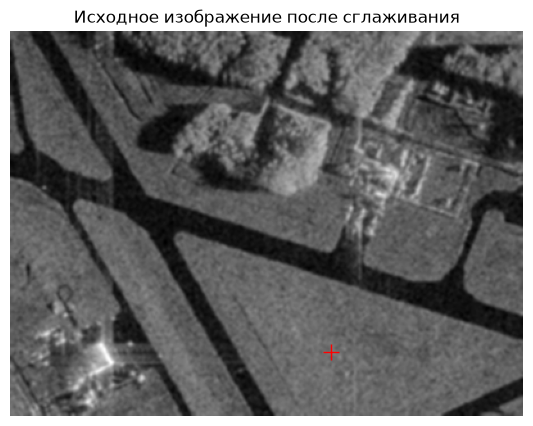

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('sar_1.jpg')
if image is None:
    raise FileNotFoundError('Положите картинку газона рядом с ноутбуком')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_gray = cv2.GaussianBlur(image_gray, (5, 5), 1)

plt.figure(figsize=(7, 5))
plt.imshow(image_gray, cmap='gray')
plt.plot(250, 250, 'r+', markersize=12)
plt.title('Исходное изображение после сглаживания')
plt.axis('off')
plt.show()

### Критерий средней яркости и разрастание региона


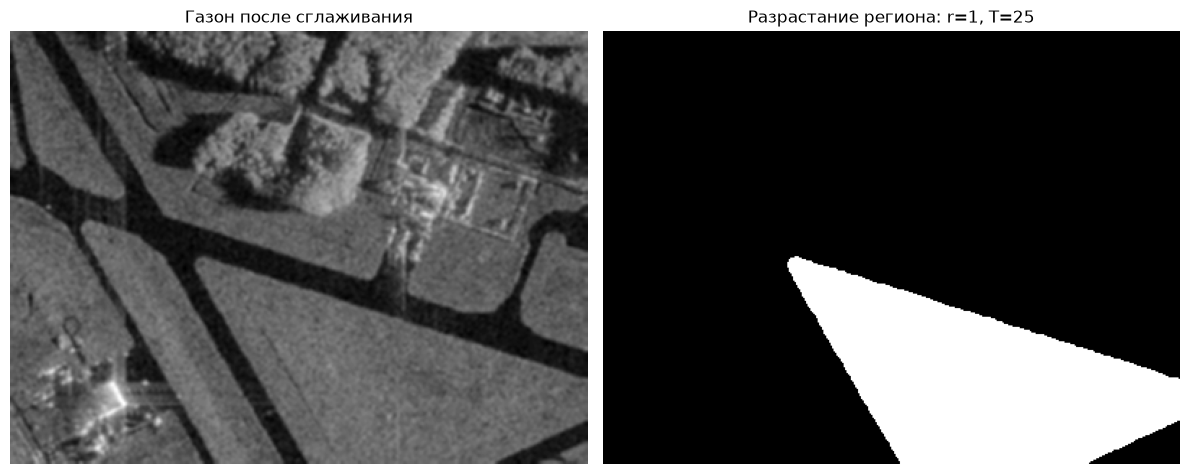

In [4]:
def homo_average(img, mask, T):
    average = np.mean(img[mask > 0])
    return np.abs(img - average) <= T


def region_growing(image, seed_point, homo_fun, r, T):
    image = image.astype(np.float32)
    mask = np.zeros(image.shape, dtype=np.uint8)
    mask[seed_point] = 1
    kernel = np.ones((2 * r + 1, 2 * r + 1), dtype=np.uint8)

    while True:
        neighbors = (cv2.dilate(mask, kernel) > 0) & (mask == 0)
        new_pixels = neighbors & homo_fun(image, mask, T)
        if not np.any(new_pixels):
            break
        mask[new_pixels] = 1

    return mask * 255


seed_point = (250, 250)
r = 1
T = 25
mask_avg = region_growing(image_gray, seed_point, homo_average, r, T)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title('Газон после сглаживания')
axes[1].imshow(mask_avg, cmap='gray')
axes[1].set_title(f'Разрастание региона: r={r}, T={T}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вывод.** После сглаживания при начальной точке `(250, 250)`, `r=1` и `T=25` выделяется практически весь видимый треугольный участок газона. Тёмные дорожки ограничивают его разрастание. Это визуальная оценка: отдельные пограничные пиксели могут быть выделены неточно.

## 2. Собственный критерий однородности


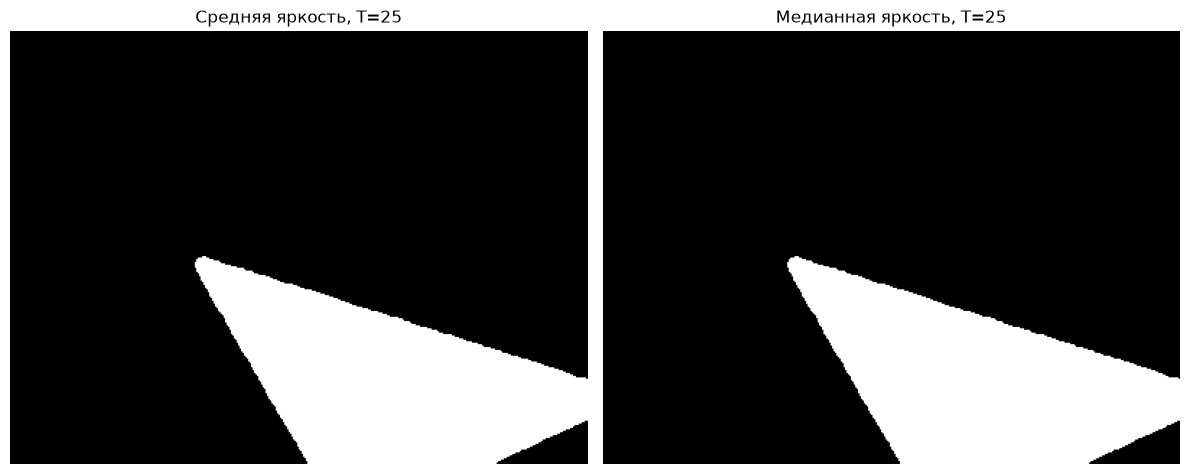

Площадь по среднему: 21548 пикселей
Площадь по медиане: 21548 пикселей


In [5]:
def homo_median(img, mask, T):
    median = np.median(img[mask > 0])
    return np.abs(img - median) <= T


mask_median = region_growing(image_gray, seed_point, homo_median, r, T)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(mask_avg, cmap='gray')
axes[0].set_title('Средняя яркость, T=25')
axes[1].imshow(mask_median, cmap='gray')
axes[1].set_title('Медианная яркость, T=25')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print('Площадь по среднему:', np.count_nonzero(mask_avg), 'пикселей')
print('Площадь по медиане:', np.count_nonzero(mask_median), 'пикселей')

**Вывод.** Оба критерия выделяют один и тот же основной участок газона и дают визуально близкие результаты. При выбранных параметрах площади обеих масок совпали: 21 548 пикселей. На данном изображении нет заметного преимущества одного критерия над другим. Площадь маски показывает размер выделенной области, а не точность сегментации.

## 3. Подсчёт пальм: watershed + distance transform


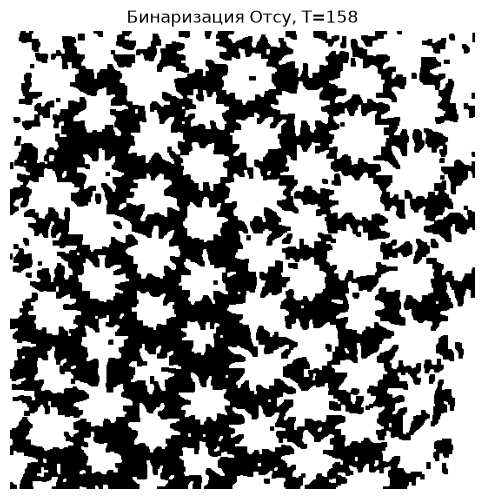

In [6]:
palm = cv2.imread('palm_1.JPG')
if palm is None:
    raise FileNotFoundError('Положите картинку пальм рядом с ноутбуком')
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
palm_gray = cv2.GaussianBlur(palm_gray, (5, 5), 1)

T_otsu, thresh = cv2.threshold(
    palm_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
kernel = np.ones((3, 3), dtype=np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
thresh = cv2.morphologyEx(
    thresh, cv2.MORPH_CLOSE, np.ones((5, 5), dtype=np.uint8)
)

plt.figure(figsize=(6, 6))
plt.imshow(thresh, cmap='gray')
plt.title(f'Бинаризация Отсу, T={T_otsu:.0f}')
plt.axis('off')
plt.show()

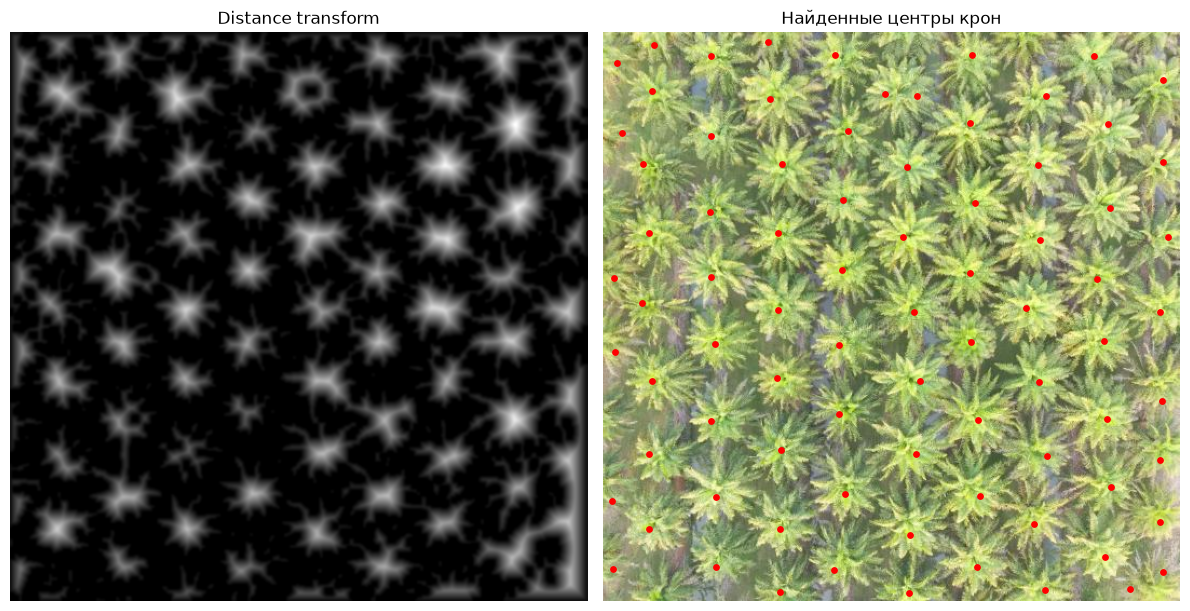

In [7]:
bordered = cv2.copyMakeBorder(
    thresh, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0
)
dist = cv2.distanceTransform(bordered, cv2.DIST_L2, 5)[1:-1, 1:-1]
dist = cv2.GaussianBlur(dist, (5, 5), 1)

local_max = cv2.dilate(dist, np.ones((31, 31), dtype=np.uint8))
sure_fg = np.uint8((dist == local_max) & (dist > 7)) * 255

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(dist, cmap='gray')
axes[0].set_title('Distance transform')
axes[1].imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))
y, x = np.where(sure_fg > 0)
axes[1].scatter(x, y, c='red', s=15)
axes[1].set_title('Найденные центры крон')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Watershed и подсчёт


Автоматическая оценка числа пальм: 81


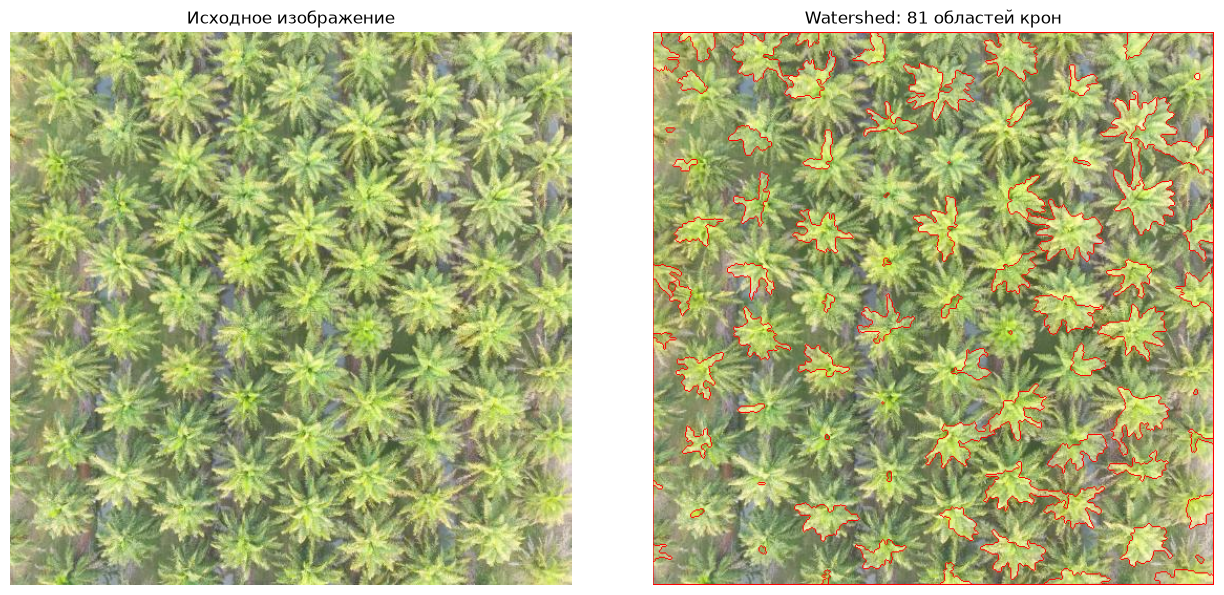

In [8]:
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1

sure_bg = cv2.dilate(thresh, kernel, iterations=2)
unknown = cv2.subtract(sure_bg, sure_fg)
markers[unknown == 255] = 0

markers = cv2.watershed(cv2.GaussianBlur(palm, (5, 5), 1), markers)
palm_labels = np.unique(markers[markers > 1])
palm_count = len(palm_labels)
print('Автоматическая оценка числа пальм:', palm_count)

result = palm.copy()
result[markers == -1] = [0, 0, 255]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))
axes[0].set_title('Исходное изображение')
axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'Watershed: {palm_count} областей крон')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()